# Analyzing Airport Networks — Participant 1: Context and Data

**Question:** What real-world problem are we exploring, and what do the OpenFlights tables contain?

**Graph-theory topics:** modelling a real system as a graph $G=(V,E)$; vertices and edges;
directed versus undirected graphs; what a graph abstraction can and cannot tell us.

**Learning outcome:** explain how an aviation problem becomes a graph model, and describe the
dataset's origin, contents and limitations.

*How to run:* put the OpenFlights `.dat` files in a `data/` folder next to this notebook, then
**Restart & Run All**. Requires `pandas`, `networkx`, `matplotlib` and (optional, for the
interactive globe) `plotly`.

*Reference:* this project was inspired by the Kaggle notebook
[Analyzing Airport Networks](https://www.kaggle.com/code/claasresow/analyzing-airport-networks)
by Claas Resow. The analysis and text below are our own; where we checked that notebook's claims
against the data, we note the differences.

---
## 1. The real-world problem

Air travel depends on a small number of very well-connected **hub** airports. When a hub fails,
the disruption spreads far beyond it. On **21 March 2025**, a fire at an electrical substation
closed **London Heathrow** for the whole day; Flightradar24 estimated that **more than 1,350
flights** to and from Heathrow were affected
([Irish News](https://www.irishnews.com/news/uk/heathrow-closed-all-day-following-electrical-substation-fire-KX7LAY3AUNK6TNKLEI7MUEHGGY/),
[AP via WJLA](https://wjla.com/news/nation-world/substation-fire-at-londons-heathrow-airport-knocks-out-power-disrupts-thousands-of-flights-international-travel-hub-diverted-gatwick-charles-de-gaulle-shannon-united-kingdom)).

**Scenario.** We act as analysts for an aviation-planning team that wants to understand the
*structure* of the global airport network. Our three questions:

1. **Hubs** — which airports have the most direct connections?
2. **Bridges** — which airports link parts of the network that would otherwise be poorly connected?
3. **Disruption** — if an important airport is removed, how much connectivity is lost?

**What this project is not:** it is descriptive graph analysis. We do not train an AI model to
predict flights, passenger numbers or airport failures.

In [62]:
import pandas as pd
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
from collections import Counter

DATA = "data"

---
## 2. The data: OpenFlights

* **Source:** [openflights.org/data.php](https://openflights.org/data.php), also mirrored on
  [GitHub](https://github.com/jpatokal/openflights/tree/master/data).
* **Licence:** Open Database License (ODbL); individual contents under the Database Contents
  License. We must credit OpenFlights.
* **Origin:** route data was imported from *Airline Route Mapper*; airport data comes from
  *OurAirports* and *DAFIF*.
* **Age:** the route data was **last updated in June 2014** and OpenFlights describes it as being
  of historical value only. Our network is a 2014 snapshot.

**Important loading detail:** OpenFlights writes missing values as `\N`. Pandas does not treat
`\N` as missing by default, so we tell it to (`na_values="\\N"`). Without this, missing values
look like real text.

In [63]:
route_cols = ["airline", "airline_id", "src", "src_id", "dst", "dst_id",
              "codeshare", "stops", "equipment"]
airport_cols = ["airport_id", "name", "city", "country", "iata", "icao", "lat", "lon",
                "altitude", "utc_offset", "dst_rule", "tz", "type", "source"]
airline_cols = ["airline_id", "name", "alias", "iata", "icao", "callsign", "country", "active"]
country_cols = ["name", "iso_code", "dafif_code"]
plane_cols = ["name", "iata", "icao"]

def load(file, cols):
    return pd.read_csv(f"{DATA}/{file}", header=None, names=cols,
                       na_values="\\N", keep_default_na=False)

routes = load("routes.dat", route_cols)
airports = load("airports.dat", airport_cols)
airlines = load("airlines.dat", airline_cols)
countries = load("countries.dat", country_cols)
planes = load("planes.dat", plane_cols)

### 2.1 Five files: two used, three available but unused

In [64]:
inventory = pd.DataFrame([
    ["routes.dat",    len(routes),    "Airline, source & destination airport, codeshare, stops, aircraft",
     "USED – builds the graph"],
    ["airports.dat",  len(airports),  "Name, city, country, IATA/ICAO codes, coordinates",
     "USED – labels and map coordinates"],
    ["airlines.dat",  len(airlines),  "Airline names, codes, country",
     "Not used – could compare airlines"],
    ["countries.dat", len(countries), "Country names and ISO codes",
     "Not used – could group airports by country"],
    ["planes.dat",    len(planes),    "Aircraft names and codes",
     "Not used – aircraft types not studied"],
], columns=["file", "rows", "contents", "role in our project"])
inventory

,file,rows,contents,role in our project
0,routes.dat,67663,"Airline, source & destination airport, codesha...",USED – builds the graph
1,airports.dat,7698,"Name, city, country, IATA/ICAO codes, coordinates",USED – labels and map coordinates
2,airlines.dat,6162,"Airline names, codes, country",Not used – could compare airlines
3,countries.dat,261,Country names and ISO codes,Not used – could group airports by country
4,planes.dat,246,Aircraft names and codes,Not used – aircraft types not studied


*Note:* OpenFlights also provides `airports-extended.dat`, which adds train stations, ferry
terminals and unverified user contributions. We use `airports.dat` because it contains airports only.

### 2.2 What a route record looks like

In [65]:
routes.head()

,airline,airline_id,src,src_id,dst,dst_id,codeshare,stops,equipment
0,2B,410.0,AER,2965.0,KZN,2990.0,,0,CR2
1,2B,410.0,ASF,2966.0,KZN,2990.0,,0,CR2
2,2B,410.0,ASF,2966.0,MRV,2962.0,,0,CR2
3,2B,410.0,CEK,2968.0,KZN,2990.0,,0,CR2
4,2B,410.0,CEK,2968.0,OVB,4078.0,,0,CR2


Each row says: *airline X lists a service from airport A to airport B.* Key fields:

| Field | Meaning |
|---|---|
| `src`, `dst` | 3-letter IATA (or 4-letter ICAO) airport codes — these become our vertices |
| `codeshare` | `Y` = the flight is operated by a different airline (same physical flight listed again) |
| `stops` | `0` = direct |
| `equipment` | aircraft type codes |

There is **no** column for number of flights, passengers, seats, distance or time.

In [66]:
print("Codeshare rows:", (routes["codeshare"] == "Y").sum(), "of", len(routes))
print("Stops:", routes["stops"].value_counts().to_dict())
print("Distinct airlines in routes:", routes["airline"].nunique())

Codeshare rows: 14597 of 67663
Stops: {0: 67652, 1: 11}
Distinct airlines in routes: 568


### 2.3 Missing and unmatched values

In [67]:
missing = pd.DataFrame({
    "routes.dat": routes.isna().sum(),
}).query("`routes.dat` > 0")
print("Missing values in routes.dat (after reading \\N as missing):")
display(missing)
print("Airports in airports.dat with no IATA code:", airports["iata"].isna().sum())

iata_codes = set(airports["iata"].dropna())
unmatched = ~routes["src"].isin(iata_codes) | ~routes["dst"].isin(iata_codes)
print("Route rows whose source or destination code is not in airports.dat:", unmatched.sum())

Missing values in routes.dat (after reading \N as missing):


,routes.dat
airline_id,479
src_id,220
dst_id,221


Airports in airports.dat with no IATA code: 1626
Route rows whose source or destination code is not in airports.dat: 729


**Takeaway:** the airport *codes* in `routes.dat` are always present, so every row can become an
edge. Some numeric IDs are missing, and some codes have no coordinates in `airports.dat` — these
airports stay in the graph but cannot be drawn on the map.

---
## 3. From data to graph

**Vertices** $V$: airports that appear in `routes.dat` (by IATA code).
**Edges** $E$: an edge $\{u,v\}$ exists if at least one route is listed between $u$ and $v$
in either direction.

### 3.1 Directed or undirected?
Flights do have a direction, so a **directed** graph (arrows $u \to v$) is the natural first model.
We check how often the reverse route also exists:

In [68]:
r = routes[routes["src"] != routes["dst"]]                  # ignore the self-loop row
directed_pairs = set(zip(r["src"], r["dst"]))
reciprocal = sum((b, a) in directed_pairs for a, b in directed_pairs)
print(f"Self-loop rows removed: {(routes['src'] == routes['dst']).sum()}")
print(f"Distinct directed airport pairs: {len(directed_pairs):,}")
print(f"...with the reverse direction also listed: {reciprocal:,} ({reciprocal/len(directed_pairs):.1%})")
print(f"...one-way only: {len(directed_pairs) - reciprocal:,}")

Self-loop rows removed: 1
Distinct directed airport pairs: 37,594
...with the reverse direction also listed: 36,676 (97.6%)
...one-way only: 918


**Decision:** about 98% of directed pairs have a return route, so treating the network as
**undirected** loses very little — and our questions are about *whether* airports are connected,
not which way planes fly. We keep the graph **simple**: one edge per airport pair, no self-loops.
The number of route rows for each pair is stored only as an extra attribute (`records`); it is
*not* flight frequency.

In [69]:
pair_records = Counter(tuple(sorted(p)) for p in zip(r["src"], r["dst"]))
G = nx.Graph()
for (a, b), n in pair_records.items():
    G.add_edge(a, b, records=n)

ap = airports.dropna(subset=["iata"]).drop_duplicates("iata").set_index("iata")
nx.set_node_attributes(G, ap["name"].to_dict(), "name")
nx.set_node_attributes(G, ap["country"].to_dict(), "country")

summary = pd.DataFrame({
    "value": [len(routes), len(directed_pairs), G.number_of_nodes(), G.number_of_edges(),
              len(airports), sum(v not in ap.index for v in G)],
}, index=["route rows", "distinct directed pairs", "vertices |V| (airports)",
          "edges |E| (undirected connections)", "airports listed in airports.dat",
          "graph airports with no coordinates"])
summary

,value
route rows,67663
distinct directed pairs,37594
vertices |V| (airports),3425
edges |E| (undirected connections),19256
airports listed in airports.dat,7698
graph airports with no coordinates,163


Most of the 7,698 airports in `airports.dat` never appear in a route, so they are **not** vertices.

### 3.2 A small example: Singapore, Kuala Lumpur and Bangkok

In [70]:
trio = ["SIN", "KUL", "BKK"]
for a, b in [("SIN", "KUL"), ("KUL", "BKK"), ("SIN", "BKK")]:
    fwd = ((r["src"] == a) & (r["dst"] == b)).sum()
    back = ((r["src"] == b) & (r["dst"] == a)).sum()
    print(f"{a}-{b}: {fwd} route rows {a}->{b}, {back} rows {b}->{a}  ->  ONE undirected edge")
print(f"\nSIN connects directly to {G.degree('SIN')} airports (its degree).")

SIN-KUL: 10 route rows SIN->KUL, 10 rows KUL->SIN  ->  ONE undirected edge
KUL-BKK: 9 route rows KUL->BKK, 9 rows BKK->KUL  ->  ONE undirected edge
SIN-BKK: 9 route rows SIN->BKK, 10 rows BKK->SIN  ->  ONE undirected edge

SIN connects directly to 125 airports (its degree).


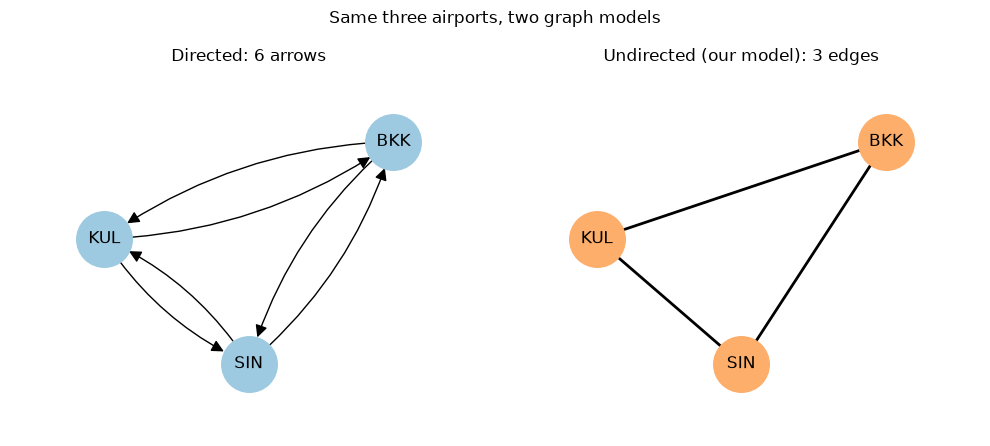

In [71]:
pos = {"SIN": (0, 0), "KUL": (-0.6, 0.9), "BKK": (0.6, 1.6)}
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))

D = nx.DiGraph([(a, b) for a in trio for b in trio if a != b and (a, b) in directed_pairs])
nx.draw_networkx(D, pos, ax=axes[0], node_color="#9ecae1", node_size=1600,
                 arrows=True, arrowsize=18, connectionstyle="arc3,rad=0.15")
axes[0].set_title(f"Directed: {D.number_of_edges()} arrows")

U = G.subgraph(trio)
nx.draw_networkx(U, pos, ax=axes[1], node_color="#fdae6b", node_size=1600, width=2)
axes[1].set_title(f"Undirected (our model): {U.number_of_edges()} edges")
for ax in axes:
    ax.axis("off"); ax.margins(0.25)
plt.suptitle("Same three airports, two graph models")
plt.tight_layout()
plt.savefig("fig_p1_directed_vs_undirected.png", dpi=150)
plt.show()

---
## 4. The global route map

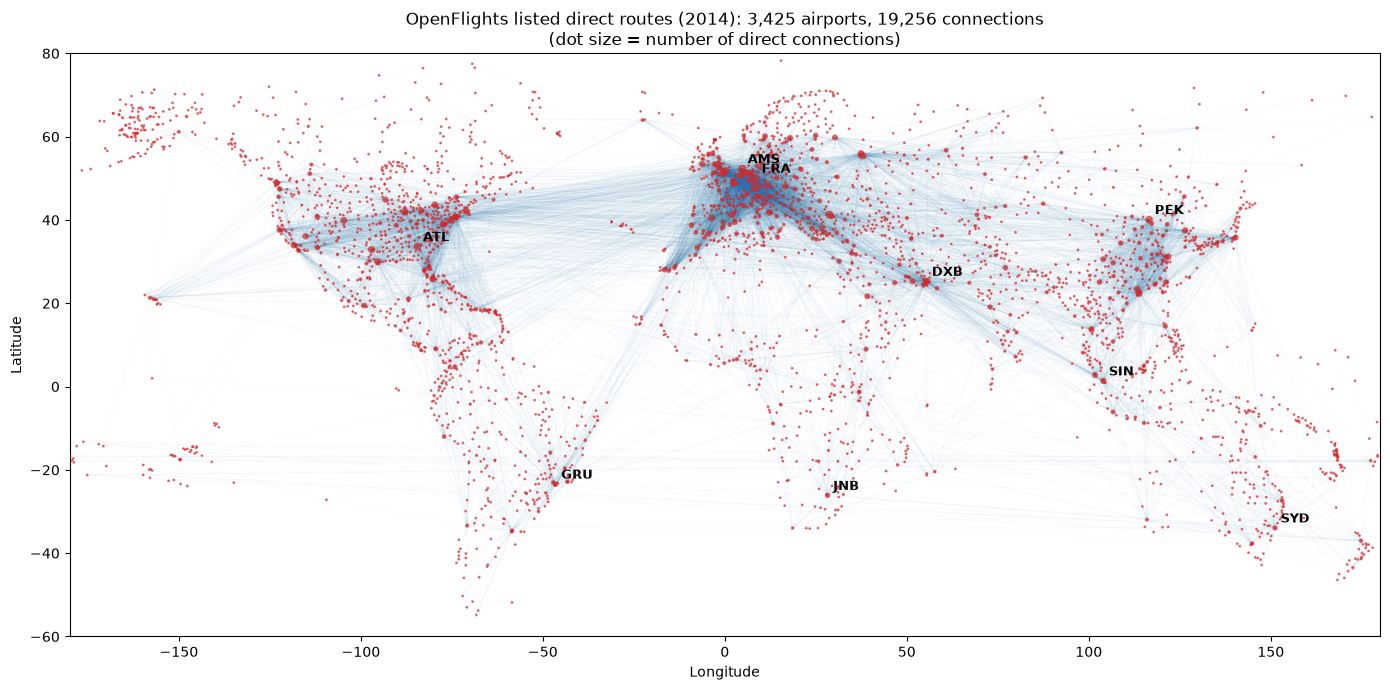

In [72]:
coords = ap[["lat", "lon"]].to_dict("index")
deg = dict(G.degree())

fig, ax = plt.subplots(figsize=(14, 7))
for a, b in G.edges():
    if a in coords and b in coords:
        ax.plot([coords[a]["lon"], coords[b]["lon"]], [coords[a]["lat"], coords[b]["lat"]],
                color="#1f77b4", alpha=0.03, linewidth=0.5)
drawn = [v for v in G if v in coords]
ax.scatter([coords[v]["lon"] for v in drawn], [coords[v]["lat"] for v in drawn],
           s=[max(1, deg[v] / 10) for v in drawn], color="#d62728", alpha=0.6, zorder=3)
for code in ["AMS", "FRA", "ATL", "PEK", "DXB", "SIN", "GRU", "JNB", "SYD"]:
    ax.annotate(code, (coords[code]["lon"], coords[code]["lat"]), fontsize=9,
                xytext=(4, 4), textcoords="offset points", weight="bold")
ax.set_title(f"OpenFlights listed direct routes (2014): {G.number_of_nodes():,} airports, "
             f"{G.number_of_edges():,} connections\n(dot size = number of direct connections)")
ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude")
ax.set_xlim(-180, 180); ax.set_ylim(-60, 80)
plt.tight_layout()
plt.savefig("fig_p1_route_map.png", dpi=150)
plt.show()

**What to point out:** dense clusters in Europe, North America and East Asia; "star" shapes around
hubs such as Dubai and Moscow; sparse coverage in Africa and the Pacific. Lines are straight on a
flat map, not real flight paths.

In [ ]:
%pip install --upgrade nbformat
pip install plotly

### 4.1 Interactive globe (optional live demo)
One trace for all edges keeps this fast. Hover over an airport to see its name and degree.
The globe is also saved as `route_globe.html`, which opens in any browser.

In [73]:
try:
    import plotly.graph_objects as go
    lons, lats = [], []
    for a, b in G.edges():
        if a in coords and b in coords:
            lons += [coords[a]["lon"], coords[b]["lon"], None]
            lats += [coords[a]["lat"], coords[b]["lat"], None]
    globe = go.Figure()
    globe.add_trace(go.Scattergeo(lon=lons, lat=lats, mode="lines",
                                  line=dict(width=0.3, color="rgba(31,119,180,0.25)"),
                                  hoverinfo="skip"))
    globe.add_trace(go.Scattergeo(
        lon=[coords[v]["lon"] for v in drawn], lat=[coords[v]["lat"] for v in drawn],
        mode="markers",
        marker=dict(size=[2 + deg[v] / 15 for v in drawn], color="#d62728", opacity=0.7),
        text=[f"{v} – {G.nodes[v].get('name', '')}<br>{deg[v]} direct connections" for v in drawn],
        hoverinfo="text"))
    globe.update_geos(projection_type="orthographic", showland=True, landcolor="rgb(240,240,240)",
                      showocean=True, oceancolor="rgb(220,235,250)", showcountries=True,
                      projection_rotation=dict(lon=100, lat=10))
    globe.update_layout(title="Listed direct routes (OpenFlights, 2014) — drag to rotate",
                        showlegend=False, height=650, margin=dict(l=0, r=0, t=50, b=0))
    globe.write_html("route_globe.html", include_plotlyjs="cdn")
    globe.show()
except ImportError:
    print("plotly not installed – run `pip install plotly` for the interactive globe.")

---
## 5. What the graph model can and cannot tell us

| The graph **shows** | The graph does **not** show |
|---|---|
| Which airports are directly linked | How many flights or passengers use a link |
| How many airports each one links to (degree) | Distance, flight time or connection time |
| Paths through the network (counted in route hops) | Whether a multi-hop path is a bookable itinerary |
| The network's structure in 2014 | Today's routes, seasonal or suspended services |

Further caveats: codeshare rows list the same physical flight more than once; a handful of rows
have one stop; some airports lack coordinates. So our results describe **structural importance**
(position in the network), not operational importance (how busy an airport is).

**Corrections compared with the reference notebook:** route-record counts are not "flight
frequency"; the data *does* contain missing values (written as `\N`); airports are identified by
IATA code, not numeric ID; a sample of the "first 150 nodes" reflects file order, not the
network's real structure.

---
## 6. Hand-over to Participant 2
Participant 2 confirms the exact construction rules (duplicates, reverse routes, weights) and
Participant 3 measures size, density and degree distribution of this graph.

**References**
* OpenFlights data: https://openflights.org/data.php (ODbL)
* Resow, C. *Analyzing Airport Networks* (Kaggle): https://www.kaggle.com/code/claasresow/analyzing-airport-networks
* Rosen, K. H. *Discrete Mathematics and Its Applications*, chapter "Graphs".